<a href="https://colab.research.google.com/github/7mid056/mutliclasses-lab-/blob/main/multiclasses_kaustlab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from IPython.display import clear_output

%pip install kagglehub catboost xgboost tqdm imbalanced-learn -q

clear_output()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
from tqdm import tqdm

In [ ]:
# Download latest version
path = kagglehub.dataset_download("mujtabamatin/air-quality-and-pollution-assessment")

print("Path to dataset files:", path)

100%|██████████| 84.1k/84.1k [00:00<00:00, 9.95MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/mujtabamatin/air-quality-and-pollution-assessment/versions/2


In [ ]:
csv_path = os.path.join(path, "updated_pollution_dataset.csv")

df = pd.read_csv(csv_path)

df.head()

,Temperature,Humidity,PM2.5,PM10,NO2,SO2,CO,Proximity_to_Industrial_Areas,Population_Density,Air Quality
0,29.8,59.1,5.2,17.9,18.9,9.2,1.72,6.3,319,Moderate
1,28.3,75.6,2.3,12.2,30.8,9.7,1.64,6.0,611,Moderate
2,23.1,74.7,26.7,33.8,24.4,12.6,1.63,5.2,619,Moderate
3,27.1,39.1,6.1,6.3,13.5,5.3,1.15,11.1,551,Good
4,26.5,70.7,6.9,16.0,21.9,5.6,1.01,12.7,303,Good


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Temperature                    5000 non-null   float64
 1   Humidity                       5000 non-null   float64
 2   PM2.5                          5000 non-null   float64
 3   PM10                           5000 non-null   float64
 4   NO2                            5000 non-null   float64
 5   SO2                            5000 non-null   float64
 6   CO                             5000 non-null   float64
 7   Proximity_to_Industrial_Areas  5000 non-null   float64
 8   Population_Density             5000 non-null   int64  
 9   Air Quality                    5000 non-null   object 
dtypes: float64(8), int64(1), object(1)
memory usage: 390.8+ KB


In [ ]:
def duplicate(df):
  duplicate = df.duplicated().sum()
  print(duplicate)
duplicate(df)

0


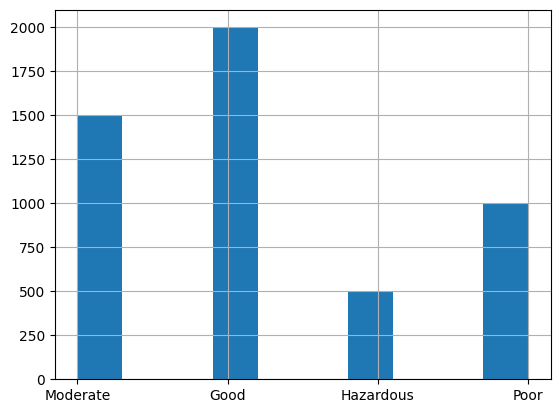

In [ ]:
target_check = df['Air Quality'].hist()
plt.show()


#the target check is inbalanced so I need to use stratified kfold

In [ ]:

df.isnull().sum()

,0
Temperature,0
Humidity,0
PM2.5,0
PM10,0
NO2,0
SO2,0
CO,0
Proximity_to_Industrial_Areas,0
Population_Density,0
Air Quality,0


In [ ]:
categorical_cols = df.select_dtypes(include =[ 'object']).columns
print(categorical_cols)


from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['Air Quality'] = le.fit_transform(df['Air Quality'])

Index(['Air Quality'], dtype='object')


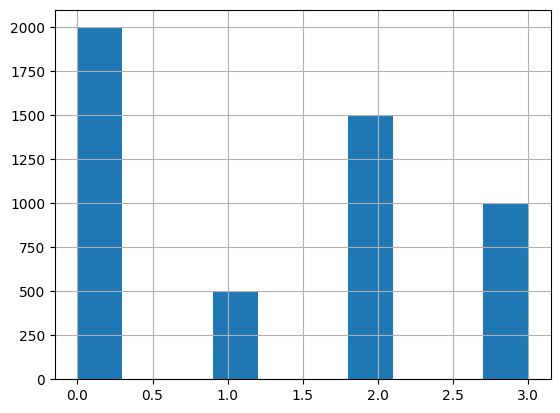

In [ ]:
df['Air Quality'].hist()
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler

numerical_cols = df.select_dtypes(include = ['number']).columns.drop('Air Quality')

scalar = StandardScaler()
df[numerical_cols] = scalar.fit_transform(df[numerical_cols])
df.head()

,Temperature,Humidity,PM2.5,PM10,NO2,SO2,CO,Proximity_to_Industrial_Areas,Population_Density,Air Quality
0,-0.034080,-0.690715,-0.608589,-0.450455,-0.844581,-0.120721,0.402303,-0.588658,-1.168163,2
1,-0.257295,0.349507,-0.726706,-0.658892,0.493329,-0.046643,0.255775,-0.671748,0.743598,2
2,-1.031106,0.292768,0.267100,0.130973,-0.226219,0.383011,0.237459,-0.893318,0.795975,2
3,-0.435867,-1.951591,-0.571933,-0.874642,-1.451700,-0.698530,-0.641707,0.740767,0.350770,0
4,-0.525153,0.040593,-0.539349,-0.519934,-0.507293,-0.654083,-0.898130,1.183909,-1.272917,0


In [ ]:
X = df.drop("Air Quality", axis=1).astype(float)
y = df["Air Quality"].astype(float)

In [ ]:
def softmax(z):
  z_shifted = z - np.max(z,axis = 1,keepdims = True )
  exp_z = np.exp(z_shifted)
  return exp_z / np.sum(exp_z, axis=1, keepdims=True)


In [ ]:
def categorical_cross_entropy(y,y_hat):
  epsilon = 1e-15
  y_hat = np.clip(y_hat,epsilon, 1-epsilon)
  loss = -np.mean(np.sum(y* np.log(y_hat), axis = 1))
  return loss

In [ ]:
def one_hot_encode(y, num_classes):
  y = np.array(y)
  m = len(y)
  one_hot = np.zeros((m,num_classes))
  for i in range(m):
    class_label = int(y[i])
    one_hot[i,class_label] = 1
  return one_hot


In [ ]:
def gradient_descent(X,y,num_classes , lr, n_iters = 1000):
  m,n = X.shape
  theta = np.zeros((n,num_classes))
  y_onehot = one_hot_encode(y,num_classes)
  losses = []
  for _ in tqdm(range(n_iters), desc="Training Multiclass Logistic Regression"):


    z = np.dot(X, theta)
    y_pred=softmax(z)
    gradient = np.dot(X.T,(y_pred - y_onehot))/m
    theta -= lr * gradient
    loss = categorical_cross_entropy(y_onehot,y_pred)
    losses.append(loss)
  return theta,losses

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score , f1_score


In [ ]:
n_splits = 3
skf = StratifiedKFold(n_splits=n_splits, shuffle = True , random_state = 42)
sr_results = {'loss':[], 'acc': [], 'f1': []}
for fold_idx, (train_index, test_index) in enumerate(skf.split(X,y)):
  print(f"\Fold {fold_idx + 1}/{n_splits}")

  X_train, X_test = X.iloc[train_index], X.iloc[test_index]
  y_train, y_test = y.iloc[train_index], y.iloc[test_index]
  theta,losses = gradient_descent(X_train,y_train, lr=0.5 , num_classes = 4)
  z = np.dot(X_test, theta)
  y_pred_proba = softmax(z)
  y_pred = np.argmax(y_pred_proba, axis = 1)
  accuracy = accuracy_score(y_test,y_pred)
  f1 = f1_score(y_test,y_pred, average='macro')
  sr_results['loss'].append(losses)
  sr_results['acc'].append(accuracy)
  sr_results['f1'].append(f1)


<>:5: SyntaxWarning: invalid escape sequence '\F'
<>:5: SyntaxWarning: invalid escape sequence '\F'
/tmp/ipykernel_866/3521818135.py:5: SyntaxWarning: invalid escape sequence '\F'
  print(f"\Fold {fold_idx + 1}/{n_splits}")


\Fold 1/3


Training Multiclass Logistic Regression: 100%|██████████| 1000/1000 [00:01<00:00, 566.69it/s]


\Fold 2/3


Training Multiclass Logistic Regression: 100%|██████████| 1000/1000 [00:01<00:00, 549.59it/s]


\Fold 3/3


Training Multiclass Logistic Regression: 100%|██████████| 1000/1000 [00:02<00:00, 388.07it/s]


In [ ]:
n_splits = 2
fold_idx = 2



  Fold 3/2


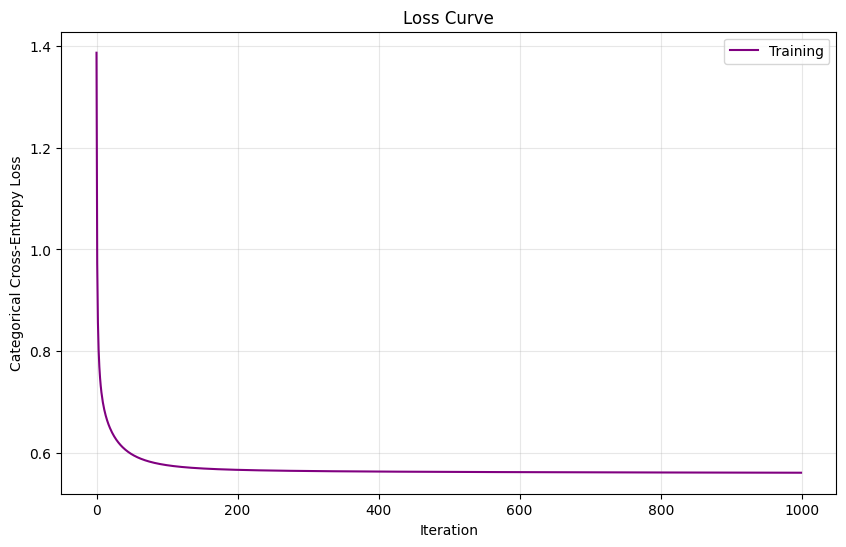

In [ ]:
avg_loss = np.mean(sr_results['loss'], axis=0)

plt.figure(figsize=(10, 6))
plt.plot(avg_loss, label='Training', color='purple')
plt.title('Loss Curve')
plt.xlabel('Iteration')
plt.ylabel('Categorical Cross-Entropy Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
print("SOFTMAX REGRESSION Performance:")
# TODO: Print the average of each evaluation metric across folds
print(f"  Accuracy:  {np.mean(sr_results['acc']):.4f}")
print(f"  F1-Score:  {np.mean(sr_results['f1']):.4f}")

SOFTMAX REGRESSION Performance:
  Accuracy:  0.7786
  F1-Score:  0.6963
